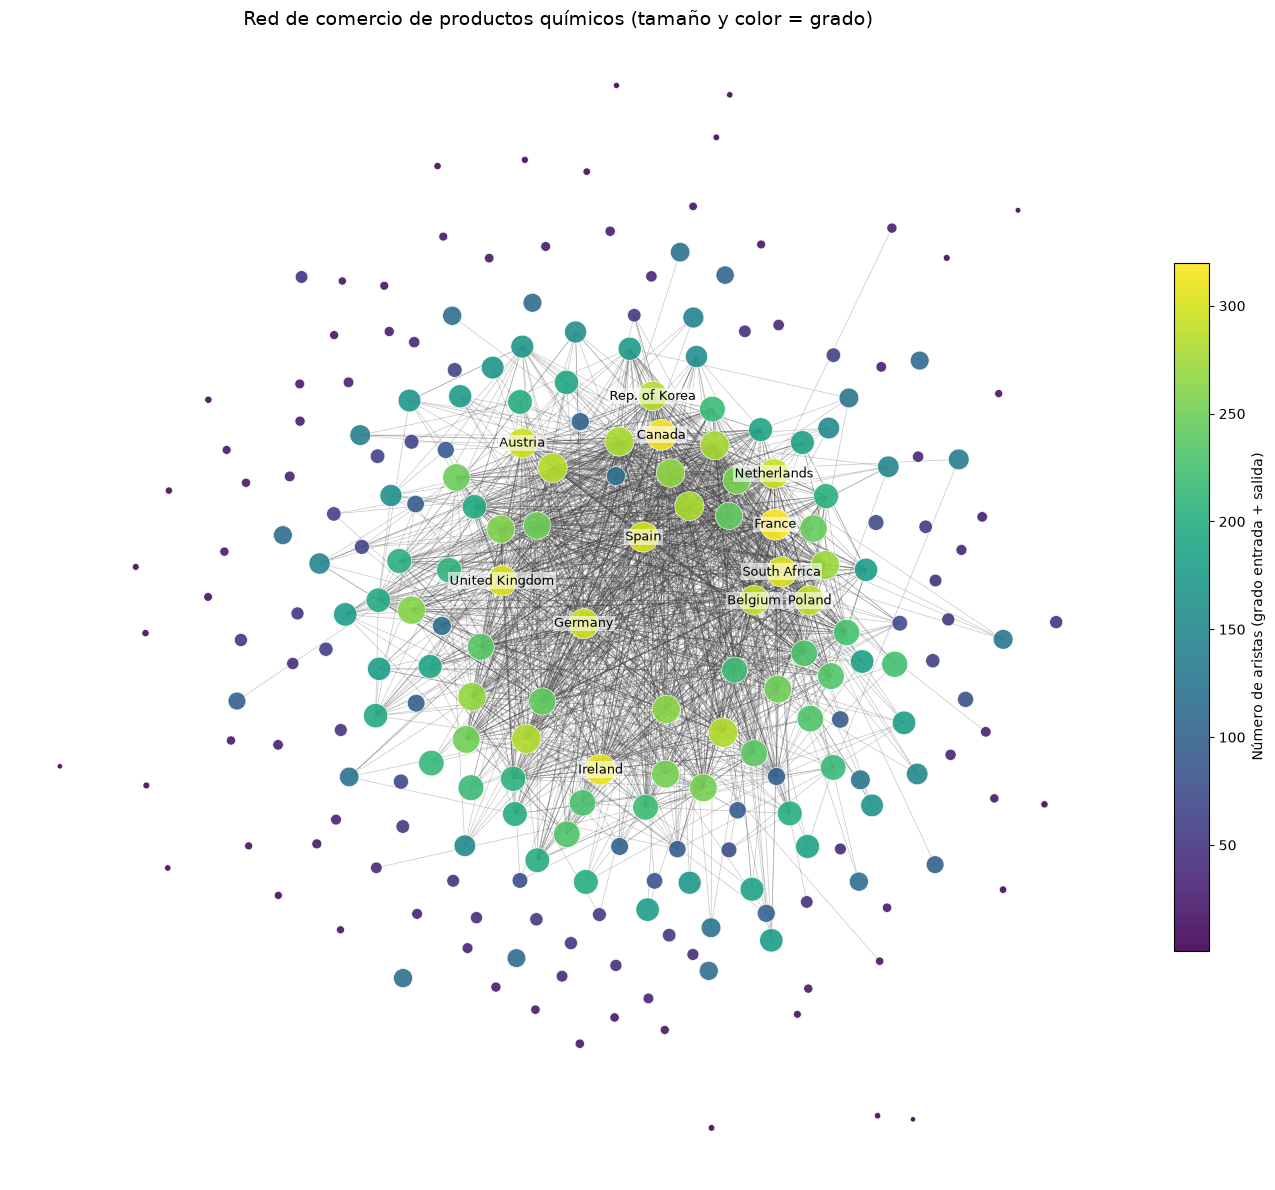

Nodos: 229 | Aristas: 13492 | Aristas dibujadas: 2024


In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ---------------- Parámetros que puedes ajustar ----------------
RUTA_CSV = "Data_Set/Red_Quimica_Comercio_Importaciones.csv"
SALIDA = "Imagenes/grafo_comercio.png"
TAM_MIN, TAM_MAX = 15, 500    # tamaño mínimo y máximo de los nodos
EXPONENTE = 1.0               # >1 exagera la diferencia entre hubs y nodos pequeños
N_ETIQUETAS = 12              # solo se rotulan los N países con más aristas
K_LAYOUT = 0.35               # más alto = nodos más separados
ITERACIONES = 200             # iteraciones del layout (más = más estable)
FACTOR_RADIAL = 0.5           # <1 abre el centro y acerca la periferia (1 = sin cambio)
SEPARAR_SOLAPES = True        # empuja los nodos que se tapan entre sí
PCT_ARISTAS = 15              # % de aristas más pesadas que se dibujan (None = todas)
# ---------------------------------------------------------------

df = pd.read_csv(RUTA_CSV)

G = nx.from_pandas_edgelist(
    df,
    source="Origen",
    target="Destino",
    edge_attr=["Peso_Volumen", "Resistencia_Ruta"],
    create_using=nx.DiGraph(),
)
G.remove_edges_from(nx.selfloop_edges(G))

# Tamaño de nodo = número de aristas (grado de entrada + grado de salida)
grado = dict(G.degree())
g = np.array([grado[n] for n in G.nodes()], dtype=float)
g_norm = (g - g.min()) / (g.max() - g.min())
tamanos = TAM_MIN + (TAM_MAX - TAM_MIN) * g_norm ** EXPONENTE

# La posición se calcula con TODAS las aristas
pos = nx.spring_layout(G, k=K_LAYOUT, iterations=ITERACIONES, seed=42)

# Reescalado radial: separa el núcleo denso y acerca los nodos lejanos,
# para aprovechar mejor el espacio de la figura (se conservan los ángulos)
xy = np.array([pos[n] for n in G.nodes()])
centro = np.median(xy, axis=0)
d = xy - centro
r = np.linalg.norm(d, axis=1)
r_ref = np.percentile(r, 90)
r_nuevo = r_ref * (r / r_ref) ** FACTOR_RADIAL
r_nuevo = np.minimum(r_nuevo, 1.3 * r_ref)   # evita que unos pocos nodos lejanos estiren la figura
escala = np.divide(r_nuevo, r, out=np.zeros_like(r), where=r > 0)
xy = centro + d * escala[:, None]


def separar_solapes(xy, tam, ancho_pt=650, iteraciones=400, holgura=1.15):
    """Aleja los nodos cuyos círculos se solapan (tam = tamaño en puntos^2)."""
    xy = xy + np.random.default_rng(0).normal(scale=1e-6, size=xy.shape)
    diam_pt = np.sqrt(tam)
    for _ in range(iteraciones):
        rango = max(np.ptp(xy[:, 0]), np.ptp(xy[:, 1]))
        dmin = (diam_pt[:, None] + diam_pt[None, :]) / 2 * holgura * rango / ancho_pt
        dif = xy[:, None, :] - xy[None, :, :]
        dist = np.linalg.norm(dif, axis=2)
        np.fill_diagonal(dist, np.inf)
        solape = np.clip(dmin - dist, 0, None)
        if solape.max() == 0:
            break
        dirs = dif / dist[..., None]
        xy = xy + 0.25 * (dirs * solape[..., None]).sum(axis=1)
    return xy


if SEPARAR_SOLAPES:
    xy = separar_solapes(xy, tamanos)

pos = {n: xy[i] for i, n in enumerate(G.nodes())}

# Solo para dibujar: quedarse con las aristas de mayor volumen
if PCT_ARISTAS is None:
    aristas_dibujo = list(G.edges())
else:
    pesos = np.array([d["Peso_Volumen"] for _, _, d in G.edges(data=True)])
    umbral = np.percentile(pesos, 100 - PCT_ARISTAS)
    aristas_dibujo = [(u, v) for u, v, d in G.edges(data=True) if d["Peso_Volumen"] >= umbral]

fig, ax = plt.subplots(figsize=(14, 12))

nx.draw_networkx_edges(
    G, pos, edgelist=aristas_dibujo, ax=ax,
    arrows=False, edge_color="#444444", alpha=0.30, width=0.5,
)
nodos = nx.draw_networkx_nodes(
    G, pos, ax=ax, node_size=tamanos,
    node_color=g, cmap=plt.cm.viridis,
    edgecolors="white", linewidths=0.5, alpha=0.9,
)

top = sorted(grado, key=grado.get, reverse=True)[:N_ETIQUETAS]
nx.draw_networkx_labels(
    G, pos, labels={n: n for n in top}, ax=ax, font_size=9,
    bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1),
)

plt.colorbar(nodos, ax=ax, shrink=0.6, label="Número de aristas (grado entrada + salida)")
ax.set_title("Red de comercio de productos químicos (tamaño y color = grado)", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(SALIDA, dpi=300, bbox_inches="tight")
plt.show()

print(f"Nodos: {G.number_of_nodes()} | Aristas: {G.number_of_edges()} "
      f"| Aristas dibujadas: {len(aristas_dibujo)}")



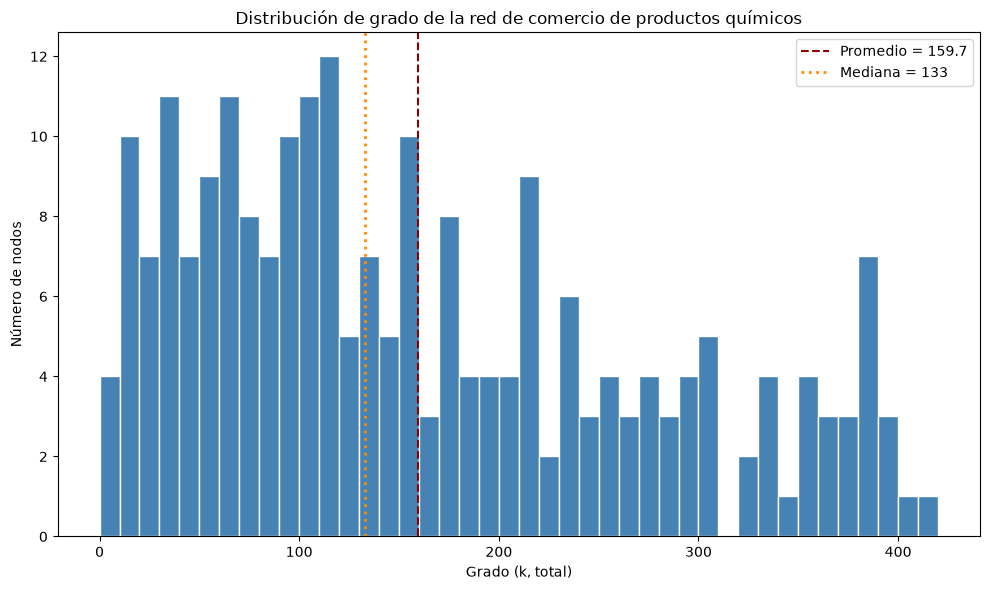

Nodos: 229 | mínimo: 1 | máximo: 416 | promedio: 159.7 | mediana: 133


In [2]:
RUTA_CSV = "Data_Set/Red_Quimica_Comercio.csv"
SALIDA = "Imagenes/distribucion_grado.png"
TIPO_GRADO = "total"      # "total" (entrada + salida), "entrada" o "salida"
ANCHO_BARRA = 10          # ancho de cada barra en unidades de grado

df = pd.read_csv(RUTA_CSV)
G = nx.from_pandas_edgelist(df, "Origen", "Destino", create_using=nx.DiGraph())
G.remove_edges_from(nx.selfloop_edges(G))

if TIPO_GRADO == "entrada":
    grados = np.array([d for _, d in G.in_degree()])
elif TIPO_GRADO == "salida":
    grados = np.array([d for _, d in G.out_degree()])
else:
    grados = np.array([d for _, d in G.degree()])

bordes = np.arange(0, grados.max() + ANCHO_BARRA, ANCHO_BARRA)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(grados, bins=bordes, color="steelblue", edgecolor="white")
ax.axvline(grados.mean(), color="darkred", linestyle="--", linewidth=1.5,
           label=f"Promedio = {grados.mean():.1f}")
ax.axvline(np.median(grados), color="darkorange", linestyle=":", linewidth=2,
           label=f"Mediana = {np.median(grados):.0f}")
ax.set_xlabel(f"Grado (k, {TIPO_GRADO})")
ax.set_ylabel("Número de nodos")
ax.set_title("Distribución de grado de la red de comercio de productos químicos")
ax.legend()
plt.tight_layout()
plt.savefig(SALIDA, dpi=300)
plt.show()

print(f"Nodos: {len(grados)} | mínimo: {grados.min()} | máximo: {grados.max()} "
      f"| promedio: {grados.mean():.1f} | mediana: {np.median(grados):.0f}")